# Generate observations configuration

Define the onshore wave observations available for your case (buoys, tide gauges, spectral sites, ...), preview them on a map, and save a **JSON (GeoJSON format)** file compatible with QGIS and the HyGloW config loader.

Workflow:

1. Set the output file name/path in the parameters cell.
2. Edit the `observations` dict below (one entry per instrument).
3. Run the preview cells to check table and map.
4. Save the JSON to disk.
5. Add/update `"onshore_waves"` in the case JSON with the saved file path.

In [1]:
import os
import sys

# Must run before any GDAL-touching import (geopandas/pyogrio, rasterio/rioxarray).
# When the kernel is launched without going through `conda activate` (e.g. VS
# Code's Jupyter extension), GDAL_DATA/PROJ_DATA are unset, and importing
# rioxarray/rasterio before geopandas.read_file() in that state leaves GDAL's
# data-path auto-discovery broken for pyogrio, raising:
#   ValueError: Found GDAL data directory at .../share/gdal but it does not
#   appear to correctly contain GDAL data files
# Setting these explicitly sidesteps the broken auto-discovery.
os.environ.setdefault("GDAL_DATA", os.path.join(sys.prefix, "share", "gdal"))
os.environ.setdefault("PROJ_DATA", os.path.join(sys.prefix, "share", "proj"))

from utils.config import PATHS, resolve
from utils import onshore_sites as obs
from utils import viz as plot

## Parameters

In [2]:
from utils.config import ONSHORE_WAVES

# Output file — defaults to the path declared in the case config ("onshore_waves").
output_observations_file = ONSHORE_WAVES
output_path = resolve(output_observations_file)

print(f"output   : {output_path}")
print(f"AoI      : {resolve(PATHS['aoi_file'])}")
print(f"topobathy: {resolve(PATHS['topobathy_file'])}")

output   : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/Observations/Netherlands_observations.json
AoI      : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/AoI_Polygons/Netherlands_AoI.shp
topobathy: /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/GRID/UGdcsm-fm_100m2coast3d_v3_era5bnd_net.tiff


## Observations dict

Edit the dictionary below. Keys are unique `instrument_id` strings.

Required per entry:
- `lon`, `lat` — WGS84 coordinates
- `type` — role used downstream (`validation`, `waves`, `spectrum`, `calibration`, `levels`, `ignore`, …)
- `institution` — data provider (e.g. `IMOS`, `NDBC`, `SPREP`)
- `recording` — approximate coverage period as a string (e.g. `"2010-2024"`)

Optional:
- `depth` — water depth in metres (`null` if unknown)
- `name` — human-readable station name
- `role` — overrides `type` when filtering by role in later notebooks
- any extra property (e.g. `msl` for tide gauges) is kept in the GeoJSON

In [3]:
observations: dict[str, dict] = {
    # Rijkswaterstaat (Waterinfo/DDL) wave-measurement stations -- Hm0/Th0/Tm-10.
    # depth is left as None: the raw NetCDFs report an undefined sampling
    # height (Bemonsteringshoogte = -999999999), so no reliable value exists.
    "AmelanderZeegat_1_1": {
        "lon": 5.4814,
        "lat": 53.5076,
        "type": "waves",
        "institution": "Rijkswaterstaat",
        "recording": "2003-12-04 to 2019-05-09",
        "depth": None,
        "name": "Amelander Zeegat, 1.1",
    },
    "AmelanderZeegat_1_2": {
        "lon": 5.48442,
        "lat": 53.5076,
        "type": "waves",
        "institution": "Rijkswaterstaat",
        "recording": "2004-02-26 to 2019-02-13",
        "depth": None,
        "name": "Amelander Zeegat, 1.2",
    },
    "EierlandseGat": {
        "lon": 4.66035,
        "lat": 53.2762,
        "type": "waves",
        "institution": "Rijkswaterstaat",
        "recording": "2000-01-01 to 2022-03-01",
        "depth": None,
        "name": "Eierlandse Gat",
    },
    "EurogeulE13": {
        "lon": 3.7418,
        "lat": 52.00918,
        "type": "waves",
        "institution": "Rijkswaterstaat",
        "recording": "2002-10-30 to 2022-03-01",
        "depth": None,
        "name": "Eurogeul, E13",
    },
    "IJmuidenMunitiestort_1": {
        "lon": 4.05702,
        "lat": 52.54922,
        "type": "waves",
        "institution": "Rijkswaterstaat",
        "recording": "2000-01-01 to 2022-03-01",
        "depth": None,
        "name": "IJmuiden, munitiestort, 1",
    },
    "PettenMeetraai01": {
        "lon": 4.55678,
        "lat": 52.80685,
        "type": "waves",
        "institution": "Rijkswaterstaat",
        "recording": "2000-12-31 to 2013-05-31",
        "depth": None,
        "name": "Petten, meetraai 01",
    },
    "StortemelkWest": {
        "lon": 4.996,
        "lat": 53.32072,
        "type": "waves",
        "institution": "Rijkswaterstaat",
        "recording": "2007-10-24 to 2022-03-01",
        "depth": None,
        "name": "Stortemelk, west",
    },
    "WestereemsWest": {
        "lon": 6.36667,
        "lat": 53.61806,
        "type": "waves",
        "institution": "Rijkswaterstaat",
        "recording": "2007-05-31 to 2022-03-01",
        "depth": None,
        "name": "Westereems, west",
    },
    "ZandmoterBoeiNoord": {
        "lon": 4.15827,
        "lat": 52.04809,
        "type": "waves",
        "institution": "Rijkswaterstaat",
        "recording": "2011-11-30 to 2011-12-31",
        "depth": None,
        "name": "Zandmoter, boei, noord",
    },
}

## Build GeoJSON and preview table

In [4]:
feature_collection = obs.dict_to_geojson(observations)
preview_df = obs.geojson_to_dataframe(feature_collection)
preview_df

,type,institution,recording,depth,name,lon,lat
instrument_id,,,,,,,
AmelanderZeegat_1_1,waves,Rijkswaterstaat,2003-12-04 to 2019-05-09,None,"Amelander Zeegat, 1.1",5.48140,53.50760
AmelanderZeegat_1_2,waves,Rijkswaterstaat,2004-02-26 to 2019-02-13,None,"Amelander Zeegat, 1.2",5.48442,53.50760
EierlandseGat,waves,Rijkswaterstaat,2000-01-01 to 2022-03-01,None,Eierlandse Gat,4.66035,53.27620
EurogeulE13,waves,Rijkswaterstaat,2002-10-30 to 2022-03-01,None,"Eurogeul, E13",3.74180,52.00918
IJmuidenMunitiestort_1,waves,Rijkswaterstaat,2000-01-01 to 2022-03-01,None,"IJmuiden, munitiestort, 1",4.05702,52.54922
PettenMeetraai01,waves,Rijkswaterstaat,2000-12-31 to 2013-05-31,None,"Petten, meetraai 01",4.55678,52.80685
StortemelkWest,waves,Rijkswaterstaat,2007-10-24 to 2022-03-01,None,"Stortemelk, west",4.99600,53.32072
WestereemsWest,waves,Rijkswaterstaat,2007-05-31 to 2022-03-01,None,"Westereems, west",6.36667,53.61806
ZandmoterBoeiNoord,waves,Rijkswaterstaat,2011-11-30 to 2011-12-31,None,"Zandmoter, boei, noord",4.15827,52.04809


## Map

Using Esri World Imagery (ArcGIS):
- Free for public and non-commercial use
- Commercial use allowed under Esri terms of service
- Attribution required: 'Tiles © Esri — Sources: Esri, Earthstar Geographics, CNES/Airbus DS, USDA, USGS, AeroGRID, IGN, and the GIS User Community'
- Max zoom ~19


(<Figure size 900x700 with 1 Axes>,
 <GeoAxes: title={'center': 'Netherlands — Case observations'}, xlabel='longitude', ylabel='latitude'>)

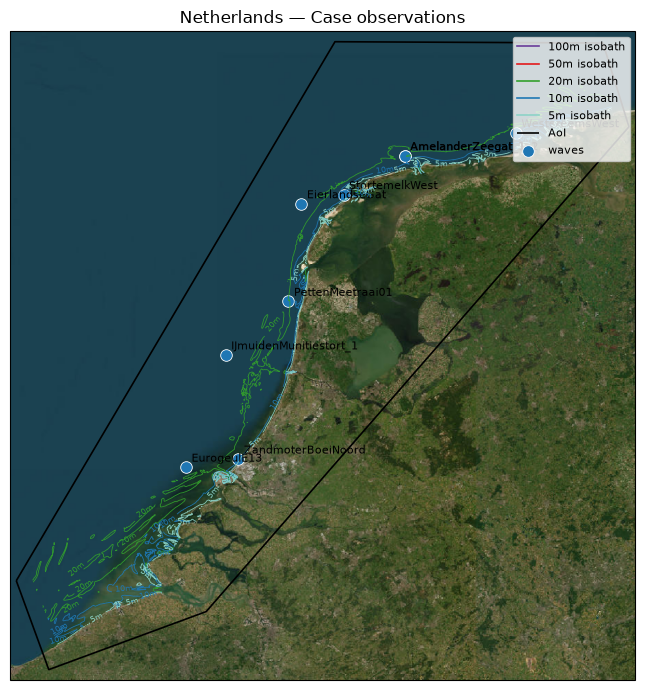

In [5]:
plot.plot_case_map(
    obs.dict_to_gdf(observations), title="Case observations", show_satellite=True
)

## Save observations JSON (GeoJSON format)

In [6]:
obs.save_geojson(feature_collection, output_path)

print(f"Wrote {len(feature_collection['features'])} feature(s) to:\n  {output_path}")

Wrote 9 feature(s) to:
  /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/Observations/Netherlands_observations.json


## Update the case JSON

After saving, add or update this key in the case JSON so downstream notebooks use your new file:

```json
"onshore_waves": "inputs/Observations/<Case>_observations.json"
```

Use the exact relative path you set in `output_observations_file`.